# YOLO Segmentation

In [ ]:
pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [ ]:
path = "/kaggle/input/datasets/pierlucadipalma/fashionmodels/reduced/000017.jpg"
model = YOLO("/kaggle/input/datasets/pierlucadipalma/bestmodel/best.pt")
results = model.predict(path)



image 1/1 /kaggle/input/datasets/pierlucadipalma/fashionmodels/reduced/000017.jpg: 512x640 1 long_sleeved_shirt, 1 trousers, 488.6ms
Speed: 2.2ms preprocess, 488.6ms inference, 4.3ms postprocess per image at shape (1, 3, 512, 640)


In [ ]:
img = results[0]
annotated = img.plot()

In [ ]:

class_ids = img.boxes.cls.cpu().numpy().astype(int)

names = [model.names[class_id] for class_id in class_ids]

print(names)

['long_sleeved_shirt', 'trousers']


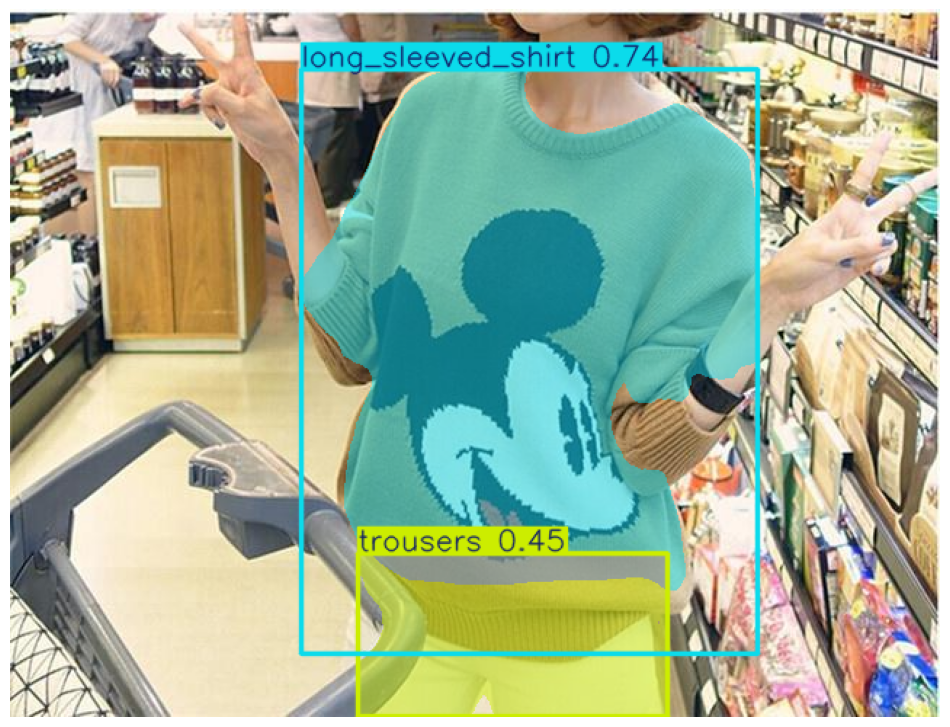

In [ ]:
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

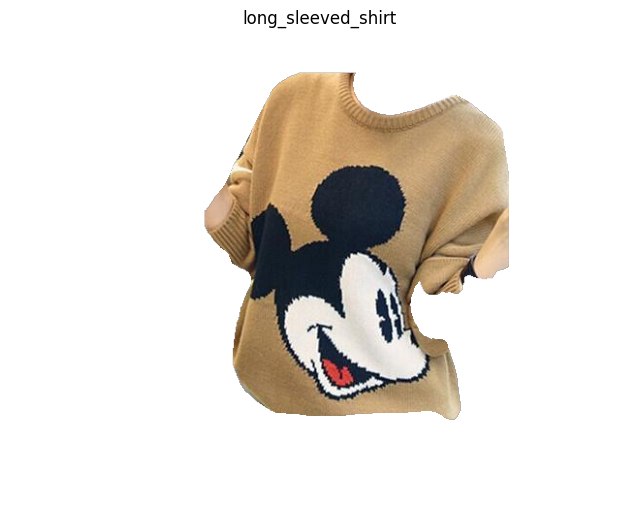

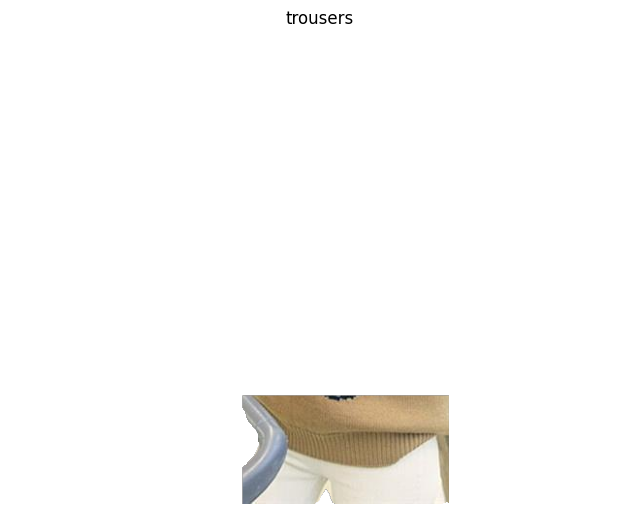

In [ ]:
result = results[0]

image = cv2.imread(path)

object_imgs = []  

for i, polygon in enumerate(result.masks.xy):

    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    polygon = polygon.astype(np.int32)
    cv2.fillPoly(mask, [polygon], 255)

    #RGBA conversion mask
    object_img = cv2.bitwise_and(image, image, mask=mask)
    object_bgra = cv2.cvtColor(object_img, cv2.COLOR_BGR2BGRA)
    object_bgra[:, :, 3] = mask  
    
    object_imgs.append(object_bgra)

    # Salvataggio su file (PNG supporta la trasparenza, JPEG no)
    cv2.imwrite(f"/kaggle/working/instance_{i}.png", object_bgra)

    # Per visualizzarla subito con matplotlib serve RGBA
    rgba_for_plot = cv2.cvtColor(object_bgra, cv2.COLOR_BGRA2RGBA)
    plt.figure(figsize=(8, 8))
    plt.imshow(rgba_for_plot)
    plt.title(names[i])
    plt.axis("off")
    plt.show()

In [ ]:
img = cv2.cvtColor(object_imgs[0], cv2.COLOR_BGR2RGBA)
imgSeg = img.copy()

# Image search #

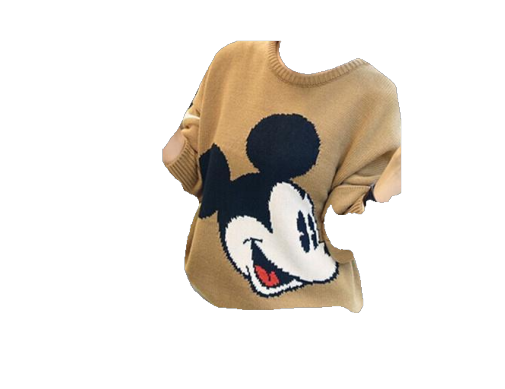

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

#img = cv2.imread(path)

#img = cv2.cvtColor(img, cv2.COLOR_BGR2RGBA)
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
!pip install git+https://github.com/openai/CLIP.git
!pip install open_clip_torch
!pip install sentence_transformers

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-lwpipcun
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-lwpipcun
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.1 MB/s eta 0:00:00
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369547 sha256=45c7434be0eceb904bb8919fb7735694d0873d18c73978f8d12e8388bd169414
  Stored in directory: /tmp/pip-ephem-wheel-cache-kz0kqubk/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 27.6 MB/s eta 0:00:0000:01


In [ ]:
import torch
import open_clip
import cv2
from sentence_transformers import util
from PIL import Image
import os
from tqdm.auto import tqdm

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-16-plus-240', pretrained="laion400m_e32")
model.to(device)

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 896, kernel_size=(16, 16), stride=(16, 16), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((896,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((896,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=896, out_features=896, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((896,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=896, out_features=3584, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3584, out_features=896, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((896,), eps=1e-05, elementwise_affine

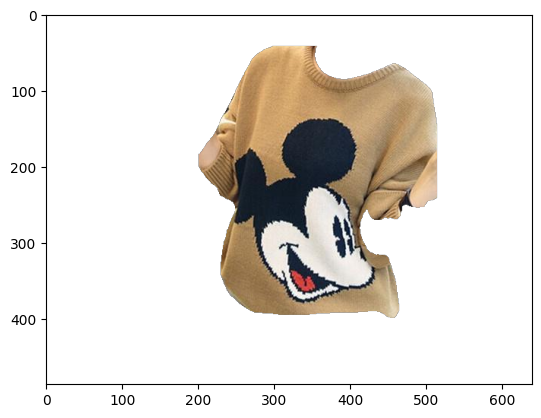

In [ ]:

plt.imshow(img)
plt.show()

In [ ]:


def imageEncoder(img):
    #img1 = crop_and_resize(img, size=224

    img1 = Image.fromarray(img).convert('RGB')
    img1 = preprocess(img1).unsqueeze(0).to(device)

    with torch.inference_mode():
        img1 = model.encode_image(img1)

    return img1


In [ ]:

folder = "/kaggle/input/datasets/pierlucadipalma/longsleevshirt/long_sleeved_shirt"

# Calcola l'embedding una sola volta per image1
img1_data = img
img1 = imageEncoder(img1_data)


In [ ]:
#file_embeddings = "embeddings.pt"
file_embeddings = "/kaggle/input/datasets/pierlucadipalma/embeddingsimage/long_sleeved_shirt_embeddings.pt"
#file_embeddings = "/kaggle/input/datasets/pierlucadipalma/clothesset/ClothesSet/LevisShirt/embeddings.pt"
if os.path.exists(file_embeddings):
    embeddings = torch.load(file_embeddings, map_location="cpu")
    print("Embedding caricati da file.")
else:
    embeddings = {}
    print("File embedding non trovato: verranno calcolati.")

Embedding caricati da file.


In [ ]:
model.eval()

risultati = []

files = [
    filename for filename in os.listdir(folder)
    if filename.lower().endswith((".png", ".jpg", ".jpeg"))
]

with torch.inference_mode():

    for filename in tqdm(files, desc="Calcolo embedding"):

        filepath = os.path.join(folder, filename)

        # salta image1 stessa
        if filepath == img1:
            continue

        # Embedding già calcolato
        if filename in embeddings:
            img2 = embeddings[filename].to(device)

        else:
            # Leggi immagine
            img_data = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)

            # Calcola embedding
            img2 = imageEncoder(img_data)

            # Salva SOLO sulla CPU
            embeddings[filename] = img2.cpu()

        # Similarità
        cos_score = util.pytorch_cos_sim(img1, img2)
        score = round(float(cos_score[0][0]) * 100, 2)

        risultati.append((filename, score))

        # Rilascia riferimento GPU
        del img2

#Salva gli embedding
#torch.save(embeddings, file_embeddings)

#print("Embedding salvati.")

Calcolo embedding:   0%|          | 0/1000 [00:00<?, ?it/s]

In [ ]:
risultati.sort(key=lambda x: x[1], reverse=True)

# Stampa i risultati
for filename, score in risultati[:10]:
    print(f"{filename}: {score}%")

000017_item1.png: 83.04%
000014_item1.png: 81.78%
000019_item1.png: 80.15%
000018_item1.png: 76.19%
000010_item1.png: 75.84%
000013_item1.png: 75.65%
000020_item1.png: 67.42%
000009_item1.png: 62.03%
002179_item2.png: 61.99%
000951_item1.png: 56.04%


In [ ]:

top10 = risultati[:10]


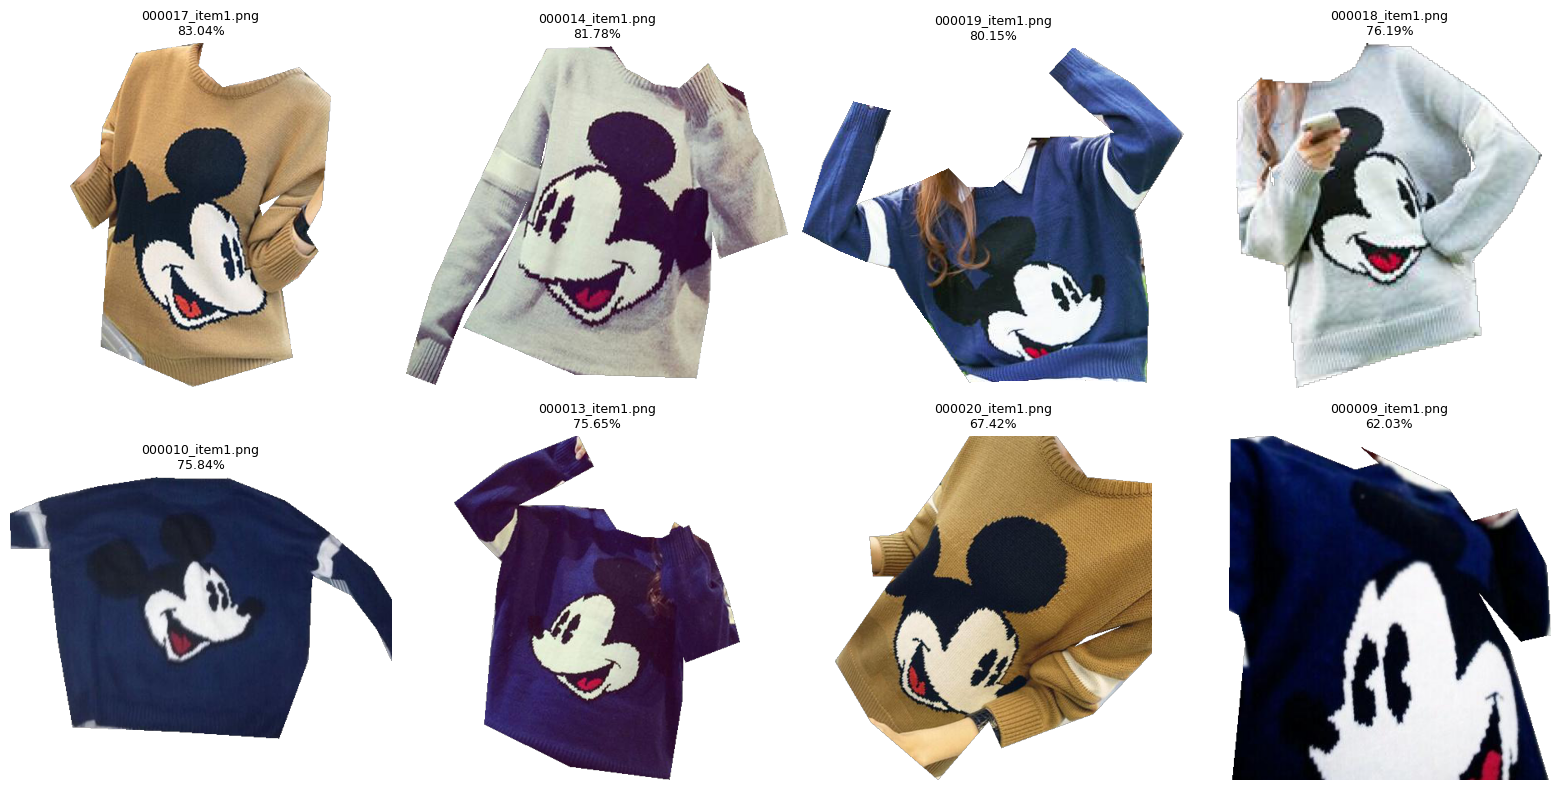

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

top_n = 8          # quante immagini mostrare
n_cols = 4
n_rows = (top_n + n_cols - 1) // n_cols  # arrotonda per eccesso

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, (filename, score) in zip(axes, risultati[:top_n]):
    filepath = os.path.join(folder, filename)
    img = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)

    # OpenCV usa BGR, matplotlib vuole RGB
    if img.ndim == 3 and img.shape[2] == 4:      # PNG con canale alpha
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(f"{filename}\n{score}%", fontsize=9)
    ax.axis("off")

# nascondi i subplot vuoti se top_n non riempie la griglia
for ax in axes[top_n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Color Retrivial #

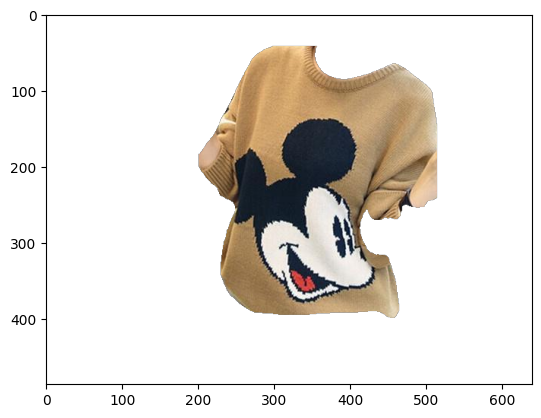

In [ ]:
img = imgSeg
#img = cv2.cvtColor(img, cv2.COLOR_BGR2RGBA)
plt.imshow(img)
plt.show()

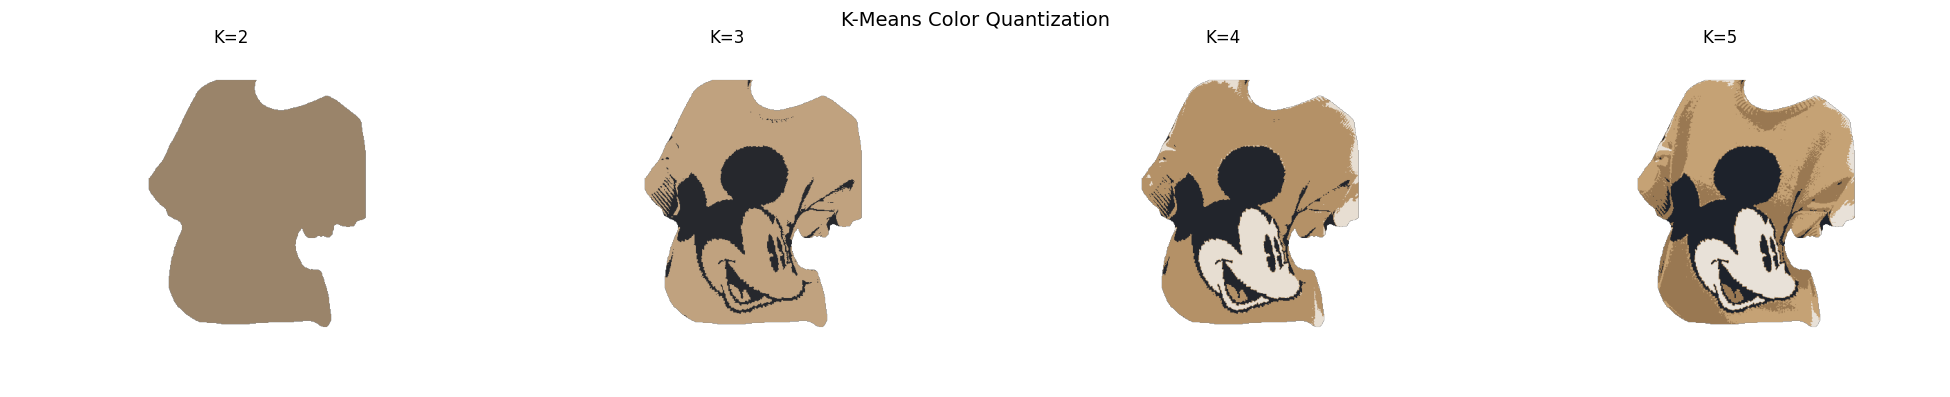

In [ ]:
pixels = img.reshape((-1, 4))
pixels = np.float32(pixels)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.85)

ks = [2, 3, 4, 5]

results_kmeans = {}  # salvo centers e labels per ogni k

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, k in enumerate(ks):
    retval, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    centers_uint8 = np.uint8(centers)

    segmented_data = centers_uint8[labels.flatten()]
    segmented_image = segmented_data.reshape(img.shape)

    results_kmeans[k] = {
        "centers": centers,          # colori (float, prima del cast)
        "centers_uint8": centers_uint8,
        "labels": labels,
        "segmented_image": segmented_image
    }

    axes[i].imshow(segmented_image)
    axes[i].set_title(f'K={k}')
    axes[i].axis('off')

plt.suptitle('K-Means Color Quantization', fontsize=14)
plt.tight_layout()
plt.show()

Il k ottimale stimato è: 2


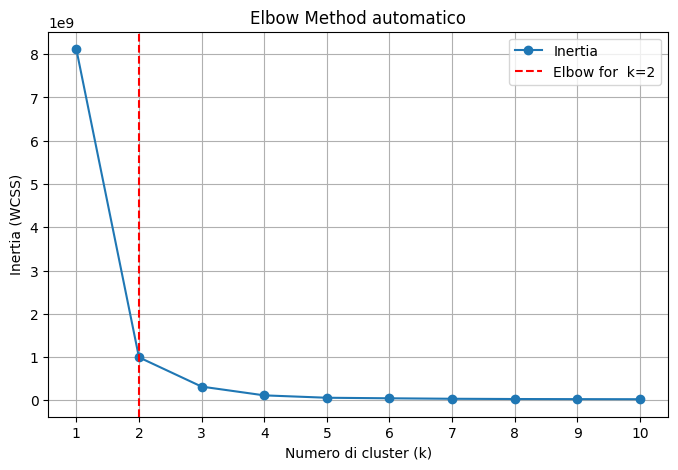

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Intervallo di k da testare
ks = list(range(1, 11))
inertias = []

for k in ks:
    compactness, labels, centers = cv2.kmeans(
        pixels,
        k,
        None,
        criteria,
        10,
        cv2.KMEANS_PP_CENTERS
    )
    inertias.append(compactness)

# Normalizzazione dei valori tra 0 e 1
x = np.array(ks, dtype=float)
y = np.array(inertias, dtype=float)

x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())

# Distanza verticale tra la curva e la retta degli estremi
line = y_norm[0] + (
    (y_norm[-1] - y_norm[0]) / (x_norm[-1] - x_norm[0])
) * (x_norm - x_norm[0])

distances = line - y_norm

# Escludiamo gli estremi: non possono essere il gomito
distances[0] = -np.inf
distances[-1] = -np.inf

best_idx = np.argmax(distances)
best_k = ks[best_idx]

print(f"Il k ottimale stimato è: {best_k}")

# Grafico
plt.figure(figsize=(8, 5))
plt.plot(ks, inertias, 'o-', label='Inertia')
plt.axvline(
    best_k,
    color='red',
    linestyle='--',
    label=f'Elbow for  k={best_k}'
)
plt.xlabel('Numero di cluster (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method automatico')
plt.xticks(ks)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
k_scelto = 5
finalCenters = results_kmeans[k_scelto]["centers_uint8"]
print(finalCenters)  

#removing alpha black channel over a certain thresh
alpha_thresh = 50  
validCenters = finalCenters[finalCenters[:, 3] > alpha_thresh]
print(validCenters)

[[  0   0   0   0]
 [ 29  34  43 255]
 [153 120  82 255]
 [232 225 216 255]
 [197 162 117 255]]
[[ 29  34  43 255]
 [153 120  82 255]
 [232 225 216 255]
 [197 162 117 255]]


In [ ]:

labels_flat = results_kmeans[k_scelto]["labels"].flatten()
conteggi = np.bincount(labels_flat, minlength=k_scelto)

# Maschera: True per i cluster con alpha > 0 (non trasparenti)
maschera_opachi = finalCenters[:, 3] > 0

centers_opachi = finalCenters[maschera_opachi]
conteggi_opachi = conteggi[maschera_opachi]
totale_opachi = conteggi_opachi.sum()

ordine = np.argsort(-conteggi_opachi)
palette_ordinata = centers_opachi[ordine]
percentuali = conteggi_opachi[ordine] / totale_opachi * 100

for colore, perc in zip(palette_ordinata, percentuali):
    print(f"Colore {colore} -> {perc:.1f}% dei pixel (esclusi trasparenti)")

Colore [197 162 117 255] -> 38.1% dei pixel (esclusi trasparenti)
Colore [153 120  82 255] -> 26.0% dei pixel (esclusi trasparenti)
Colore [ 29  34  43 255] -> 21.6% dei pixel (esclusi trasparenti)
Colore [232 225 216 255] -> 14.4% dei pixel (esclusi trasparenti)


In [ ]:
def mostra_immagini(immagini, titoli=None, colonne=4):
    n = len(immagini)
    righe = int(np.ceil(n / colonne))
    
    fig, assi = plt.subplots(righe, colonne, figsize=(colonne * 3, righe * 3))
    assi = np.array(assi).reshape(-1)  # appiattisce la griglia in un array 1D
    
    for i, ax in enumerate(assi):
        if i < n:
            ax.imshow(immagini[i])
            if titoli is not None:
                ax.set_title(titoli[i])
            ax.axis("off")
        else:
            ax.axis("off")  # nasconde le celle vuote in eccesso
    
    plt.tight_layout()
    plt.show()

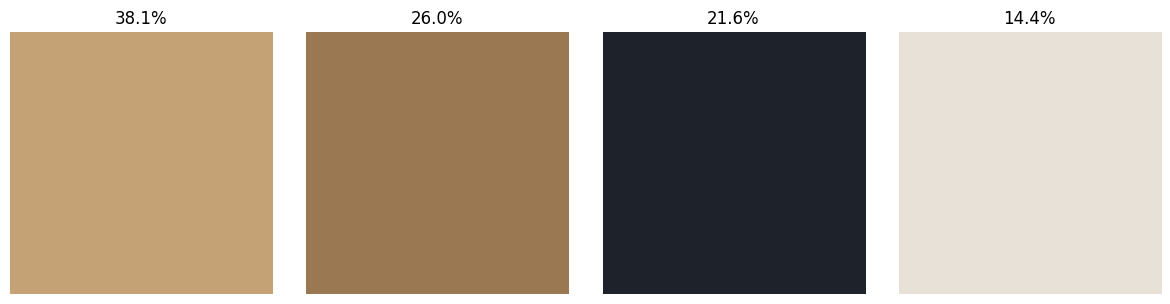

In [ ]:
altezza, larghezza = 100, 100
immagini = []

for colore in palette_ordinata:
    img = np.zeros((altezza, larghezza, 3), np.uint8)
    img[:, :, :] = colore[:3]
    immagini.append(img)

titoli = [f"{perc:.1f}%" for perc in percentuali]
mostra_immagini(immagini, titoli=titoli, colonne=4)

In [ ]:
import colorsys
def colore_complementare(rgb):
    # Da 0-255 a 0-1
    r, g, b = rgb / 255.0

    # RGB → HSV
    h, s, v = colorsys.rgb_to_hsv(r, g, b)

    # Sposta la tonalità di 180°
    h_complementare = (h + 0.5) % 1.0

    # HSV → RGB
    r, g, b = colorsys.hsv_to_rgb(
        h_complementare,
        s,
        v
    )

    # Da 0-1 a 0-255
    return np.array([r, g, b]) * 255



Palette dei colori:

Colore 1: RGB = (197, 162, 117)
Colore 2: RGB = (153, 120, 82)
Colore 3: RGB = (29, 34, 43)
Colore 4: RGB = (232, 225, 216)


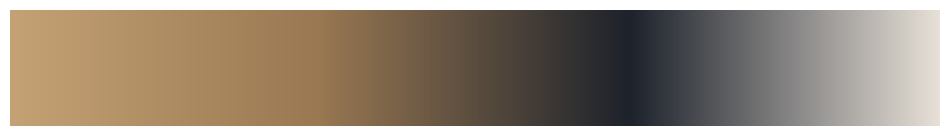

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


colori = np.array(
    [c[:3] for c in palette_ordinata[:4]],
    dtype=float
)

larghezza = 800
altezza = 100

immagine = np.zeros((altezza, larghezza, 3))

# Posizioni dei 4 colori
posizioni = np.linspace(0, larghezza - 1, len(colori))

for x in range(larghezza):

    idx = np.searchsorted(posizioni, x)

    if idx == 0:
        colore = colori[0]

    elif idx >= len(colori):
        colore = colori[-1]

    else:
        x1 = posizioni[idx - 1]
        x2 = posizioni[idx]

        t = (x - x1) / (x2 - x1)

        colore = (
            (1 - t) * colori[idx - 1]
            + t * colori[idx]
        )

    immagine[:, x] = colore

immagine = np.clip(immagine, 0, 255).astype(np.uint8)


# ============================================================
# STAMPA I COLORI
# ============================================================

print("Palette dei colori:\n")

for i, colore in enumerate(colori, start=1):
    r, g, b = colore.astype(int)

    print(
        f"Colore {i}: "
        f"RGB = ({r}, {g}, {b})"
    )

plt.figure(figsize=(12, 2))
plt.imshow(immagine)
plt.axis("off")
plt.show()


Colori complementari:

Complementare 1: RGB = (116, 152, 197)
Complementare 2: RGB = (82, 115, 153)
Complementare 3: RGB = (43, 38, 28)
Complementare 4: RGB = (216, 222, 232)


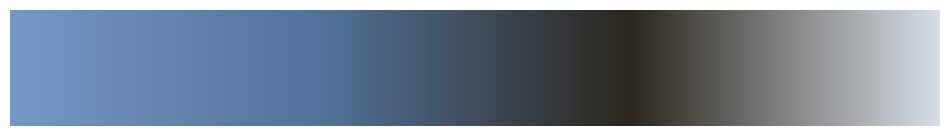

In [ ]:
colori_complementari = np.array([
    colore_complementare(colore)
    for colore in colori
])
print("\nColori complementari:\n")

larghezza = 800
altezza = 100

immagine_complementare = np.zeros((altezza, larghezza, 3))

# Posizioni dei 4 colori
posizioni = np.linspace(0, larghezza - 1, len(colori))

for x in range(larghezza):

    idx = np.searchsorted(posizioni, x)

    if idx == 0:
        colore = colori_complementari[0]

    elif idx >= len(colori):
        colore = colori_complementari[-1]

    else:
        x1 = posizioni[idx - 1]
        x2 = posizioni[idx]

        t = (x - x1) / (x2 - x1)

        colore = (
            (1 - t) * colori_complementari[idx - 1]
            + t * colori_complementari[idx]
        )

    immagine_complementare[:, x] = colore

immagine_complementare = np.clip(immagine_complementare, 0, 255).astype(np.uint8)


for i, colore in enumerate(colori_complementari, start=1):
    r, g, b = colore.astype(int)

    print(
        f"Complementare {i}: "
        f"RGB = ({r}, {g}, {b})"
    )

plt.figure(figsize=(12, 2))
plt.imshow(immagine_complementare)
plt.axis("off")
plt.show()


In [ ]:
import colorsys
import numpy as np

def colori_triadici(rgb):

    # RGB da 0-255 a 0-1
    r, g, b = rgb / 255.0

    # RGB → HSV
    h, s, v = colorsys.rgb_to_hsv(r, g, b)

    # Le due tonalità triadiche
    h2 = (h + 1/3) % 1.0      # +120°
    h3 = (h + 2/3) % 1.0      # +240°

    # HSV → RGB
    rgb2 = colorsys.hsv_to_rgb(h2, s, v)
    rgb3 = colorsys.hsv_to_rgb(h3, s, v)

    # Torna a 0-255
    rgb2 = np.array(rgb2) * 255
    rgb3 = np.array(rgb3) * 255

    return np.array([
        rgb,
        rgb2,
        rgb3
    ])

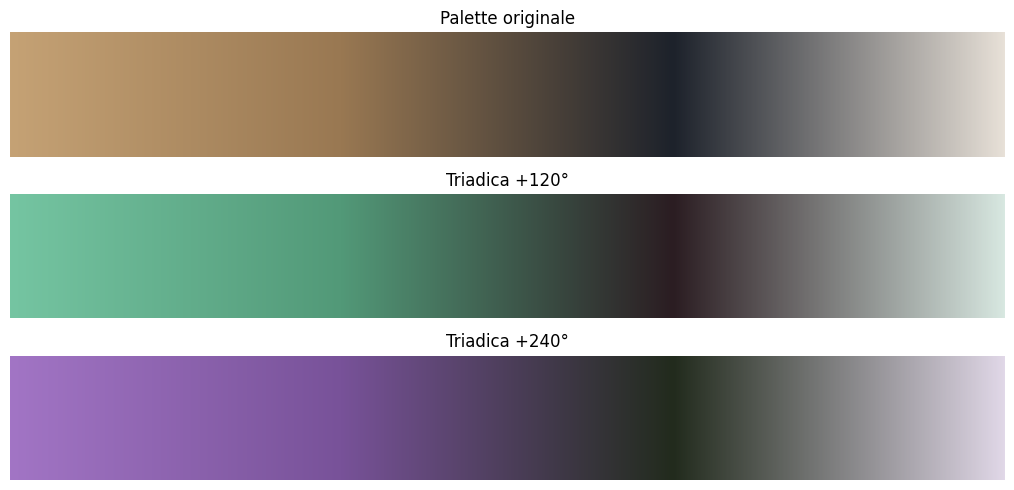


PALETTE TRIADICA


Colore 1
  Originale : RGB = (197, 162, 117)
  +120°      : RGB = (116, 197, 161)
  +240°      : RGB = (162, 116, 197)

Colore 2
  Originale : RGB = (153, 120, 82)
  +120°      : RGB = (82, 153, 120)
  +240°      : RGB = (119, 82, 153)

Colore 3
  Originale : RGB = (29, 34, 43)
  +120°      : RGB = (43, 28, 34)
  +240°      : RGB = (34, 43, 28)

Colore 4
  Originale : RGB = (232, 225, 216)
  +120°      : RGB = (216, 232, 225)
  +240°      : RGB = (225, 216, 232)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import colorsys



colori = np.array(
    [c[:3] for c in palette_ordinata[:4]],
    dtype=float
)

def triade(rgb):

    # RGB: 0-255 → 0-1
    r, g, b = rgb / 255.0

    # RGB → HSV
    h, s, v = colorsys.rgb_to_hsv(r, g, b)

    # +120° e +240°
    h2 = (h + 1/3) % 1.0
    h3 = (h + 2/3) % 1.0

    # HSV → RGB
    rgb2 = np.array(colorsys.hsv_to_rgb(h2, s, v)) * 255
    rgb3 = np.array(colorsys.hsv_to_rgb(h3, s, v)) * 255

    return np.array([rgb, rgb2, rgb3])


triadi = np.array([
    triade(colore)
    for colore in colori
])



# Riga 1 = colori originali
palette_originale = colori

# Riga 2 = +120°
palette_120 = triadi[:, 1, :]

# Riga 3 = +240°
palette_240 = triadi[:, 2, :]


# ============================================================
# FUNZIONE PER CREARE IL GRADIENTE
# ============================================================

def crea_gradiente(colori, larghezza=800, altezza=100):

    immagine = np.zeros((altezza, larghezza, 3))

    posizioni = np.linspace(
        0,
        larghezza - 1,
        len(colori)
    )

    for x in range(larghezza):

        idx = np.searchsorted(posizioni, x)

        if idx == 0:

            colore = colori[0]

        elif idx >= len(colori):

            colore = colori[-1]

        else:

            x1 = posizioni[idx - 1]
            x2 = posizioni[idx]

            t = (x - x1) / (x2 - x1)

            colore = (
                (1 - t) * colori[idx - 1]
                + t * colori[idx]
            )

        immagine[:, x] = colore

    return np.clip(
        immagine,
        0,
        255
    ).astype(np.uint8)


# ============================================================
# CREA LE 3 FASCE
# ============================================================

immagine_originale = crea_gradiente(palette_originale)
immagine_120 = crea_gradiente(palette_120)
immagine_240 = crea_gradiente(palette_240)


# ============================================================
# VISUALIZZAZIONE
# ============================================================

fig, ax = plt.subplots(
    3,
    1,
    figsize=(12, 5)
)

ax[0].imshow(immagine_originale)
ax[0].set_title("Palette originale")

ax[1].imshow(immagine_120)
ax[1].set_title("Triadica +120°")

ax[2].imshow(immagine_240)
ax[2].set_title("Triadica +240°")


for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# STAMPA DEI COLORI
# ============================================================

print("\nPALETTE TRIADICA\n")

for i in range(len(colori)):

    originale = colori[i].astype(int)
    c120 = palette_120[i].astype(int)
    c240 = palette_240[i].astype(int)

    print(f"\nColore {i + 1}")

    print(
        f"  Originale : RGB = "
        f"({originale[0]}, {originale[1]}, {originale[2]})"
    )

    print(
        f"  +120°      : RGB = "
        f"({c120[0]}, {c120[1]}, {c120[2]})"
    )

    print(
        f"  +240°      : RGB = "
        f"({c240[0]}, {c240[1]}, {c240[2]})"
    )

# Color based search #

In [ ]:
r,g,b = cv2.split(immagine_complementare)


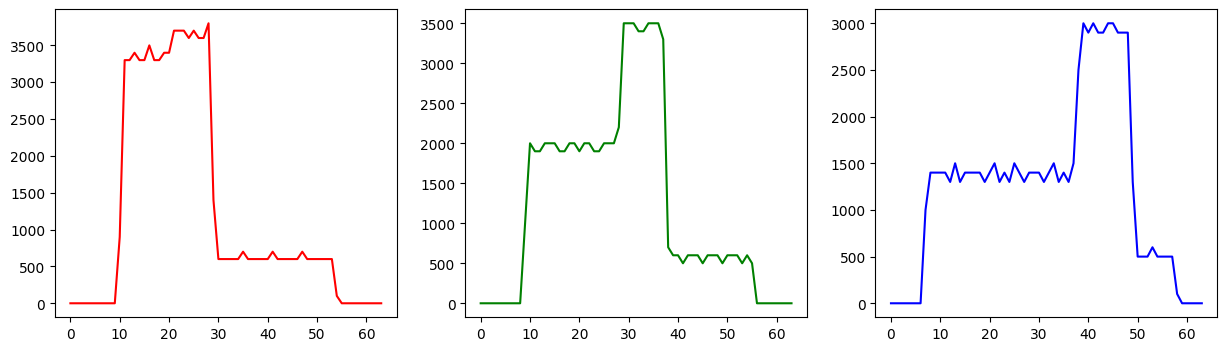

In [ ]:
red_hist   = cv2.calcHist([r], [0], None, [64], [0, 256])
green_hist = cv2.calcHist([g], [0], None, [64], [0, 256])
blue_hist  = cv2.calcHist([b], [0], None, [64], [0, 256])

fig, axis = plt.subplots(1, 3, figsize=(15, 4))
axis[0].plot(red_hist, "r")
axis[1].plot(green_hist, "g")
axis[2].plot(blue_hist, "b")
plt.show()

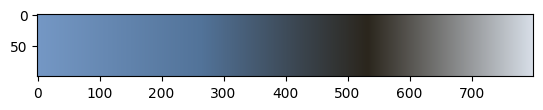

In [ ]:
plt.imshow(immagine_complementare)
plt.show()

In [ ]:

from pathlib import Path

import cv2
import numpy as np

BINS = [50, 60, 60]
RANGES = [0, 180, 0, 256, 0, 256]
CHANNELS = [0, 1, 2]

def compute_histogram(image):
    if image is None:
        raise ValueError("L'immagine query è None")

    if not isinstance(image, np.ndarray):
        raise TypeError("La query deve essere un array NumPy")

    if image.size == 0:
        raise ValueError("L'immagine è vuota")

    # OpenCV legge normalmente le immagini in formato BGR.
    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    elif image.ndim == 3 and image.shape[2] == 4:
        image = cv2.cvtColor(image, cv2.COLOR_BGRA2BGR)
    elif image.ndim != 3 or image.shape[2] != 3:
        raise ValueError(f"Formato immagine non supportato: {image.shape}")

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    hist = cv2.calcHist(
        [hsv], CHANNELS, None, BINS, RANGES
    )

    cv2.normalize(hist, hist, alpha=1, norm_type=cv2.NORM_L1)
    return hist


def search_similar_images(query_image, folder, top_k=10):
    folder = Path(folder)

    print(f"Cartella: {folder.resolve()}")
    print(f"Cartella esistente: {folder.is_dir()}")

    if not folder.is_dir():
        raise FileNotFoundError(f"Cartella non trovata: {folder.resolve()}")

    query_hist = compute_histogram(query_image)

    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    image_paths = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    print(f"Immagini trovate: {len(image_paths)}")

    results = []

    for image_path in image_paths:
        image = cv2.imread(str(image_path))

        if image is None:
            print(f"Impossibile leggere: {image_path}")
            continue

        hist = compute_histogram(image)

        distance = cv2.compareHist(
            query_hist,
            hist,
            cv2.HISTCMP_BHATTACHARYYA
        )

        results.append((image_path, distance))

    results.sort(key=lambda item: item[1])

    print(f"Risultati calcolati: {len(results)}")

    for rank, (path, distance) in enumerate(results[:top_k], start=1):
        print(f"{rank}. {path} | distanza: {distance:.4f}")

    return results[:top_k]


In [ ]:
query_image = cv2.cvtColor(immagine_complementare, cv2.COLOR_RGB2BGR)

print("Query caricata:", query_image is not None)

results = search_similar_images(
    query_image,
    folder="/kaggle/input/datasets/pierlucadipalma/trousers/trousers",
    top_k=10
)


Query caricata: True
Cartella: /kaggle/input/datasets/pierlucadipalma/trousers/trousers
Cartella esistente: True
Immagini trovate: 1000
Risultati calcolati: 1000
1. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/000926_item2.png | distanza: 0.9580
2. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/000922_item2.png | distanza: 0.9590
3. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/000075_item2.png | distanza: 0.9612
4. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/001155_item1.png | distanza: 0.9617
5. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/000799_item1.png | distanza: 0.9623
6. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/001153_item1.png | distanza: 0.9631
7. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/000787_item1.png | distanza: 0.9651
8. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/002596_item1.png | distanza: 0.9655
9. /kaggle/input/datasets/pierlucadipalma/trousers/trousers/001185_ite

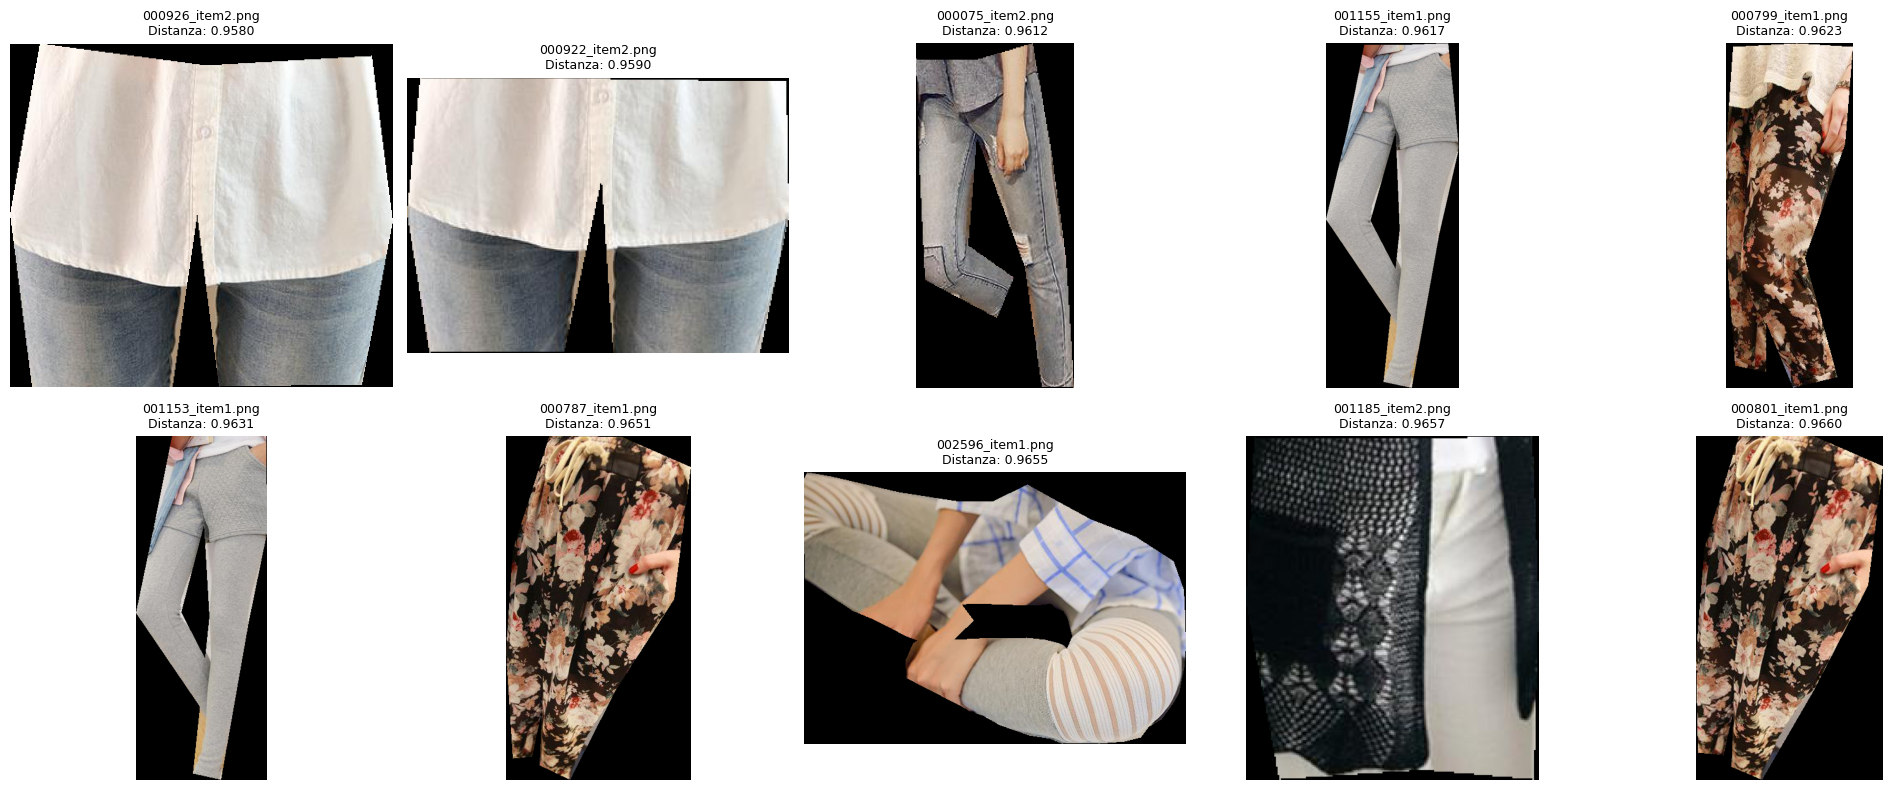

In [ ]:


fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(results):
        image_path, distance = results[i]

        img = cv2.imread(str(image_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGBA)

        ax.imshow(img)
        ax.set_title(
            f"{image_path.name}\nDistanza: {distance:.4f}",
            fontsize=9
        )
        ax.axis("off")
    else:
        ax.axis("off")

plt.tight_layout()
plt.show()

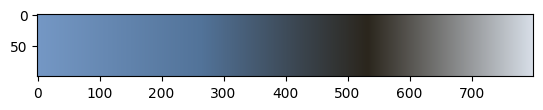

In [ ]:
plt.imshow(immagine_complementare)
plt.show()